# Exploring ModelNet10 meshes

This notebook explores object meshes and point clouds from ModelNet10. The dataset is not included. An index is built from the extracted mesh files. Extract the dataset to `ModelNet10/` in this folder, or set `MODELNET10_ROOT` to its location before running. Install pandas, NumPy, Open3D, Matplotlib, and Plotly. The mesh figures render inside the notebook.

The outputs below were generated from the corrected metadata and complete dataset.

**Data:** [ModelNet10](https://modelnet.cs.princeton.edu/download.html). Extract the 10-class dataset into `ModelNet10/` or set `MODELNET10_ROOT`. The notebook builds its own mesh index.

In [1]:
import os
from pathlib import Path
import pandas as pd

dataset_root = Path(os.environ.get("MODELNET10_ROOT", "ModelNet10"))
meshes = sorted(dataset_root.glob("*/*/*.off"))
if not meshes:
    raise FileNotFoundError("Set MODELNET10_ROOT to the extracted ModelNet10 directory.")
df = pd.DataFrame([
    {"object_id": p.stem, "class": p.parent.parent.name, "split": p.parent.name,
     "object_path": str(p.relative_to(dataset_root))}
    for p in meshes
])
print(f"Objects: {len(df)}")
print(f"Classes: {df['class'].nunique()}")
print(df['class'].value_counts())

Objects: 4899
Classes: 10
class
chair          989
sofa           780
bed            615
monitor        565
table          492
toilet         444
desk           286
dresser        286
night_stand    286
bathtub        156
Name: count, dtype: int64


In [2]:
# Set MODELNET10_ROOT if the extracted dataset is stored elsewhere.
dataset_root = Path(os.environ.get("MODELNET10_ROOT", "ModelNet10"))
df["object_path"] = df["object_path"].map(lambda path: str(dataset_root / path))

In [3]:
missing_files = [path for path in df["object_path"] if not Path(path).is_file()]
print(f"Missing mesh files: {len(missing_files)} / {len(df)}")
if missing_files:
    raise FileNotFoundError(
        f"Set MODELNET10_ROOT to the extracted ModelNet10 folder. Example missing file: {missing_files[0]}"
    )

Missing mesh files: 0 / 4899


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Class: bed
Vertices: 1016; triangles: 954


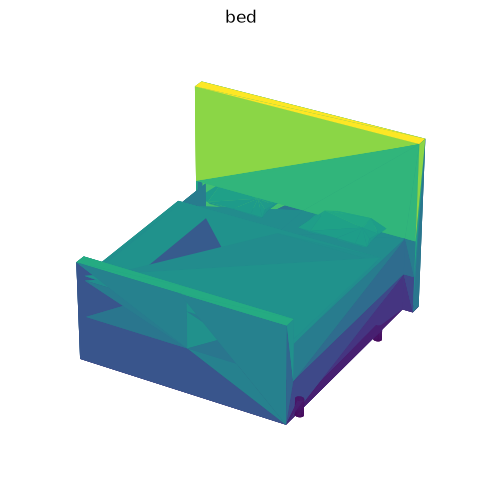

In [4]:
import open3d as o3d
import matplotlib.pyplot as plt
import numpy as np

sample_row = df.iloc[300]
mesh = o3d.io.read_triangle_mesh(sample_row["object_path"])
vertices = np.asarray(mesh.vertices)
triangles = np.asarray(mesh.triangles)
print(f"Class: {sample_row['class']}")
print(f"Vertices: {len(vertices)}; triangles: {len(triangles)}")

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot_trisurf(vertices[:, 0], vertices[:, 1], vertices[:, 2],
                triangles=triangles, cmap="viridis")
ax.set_title(sample_row["class"])
ax.set_axis_off()
plt.show()

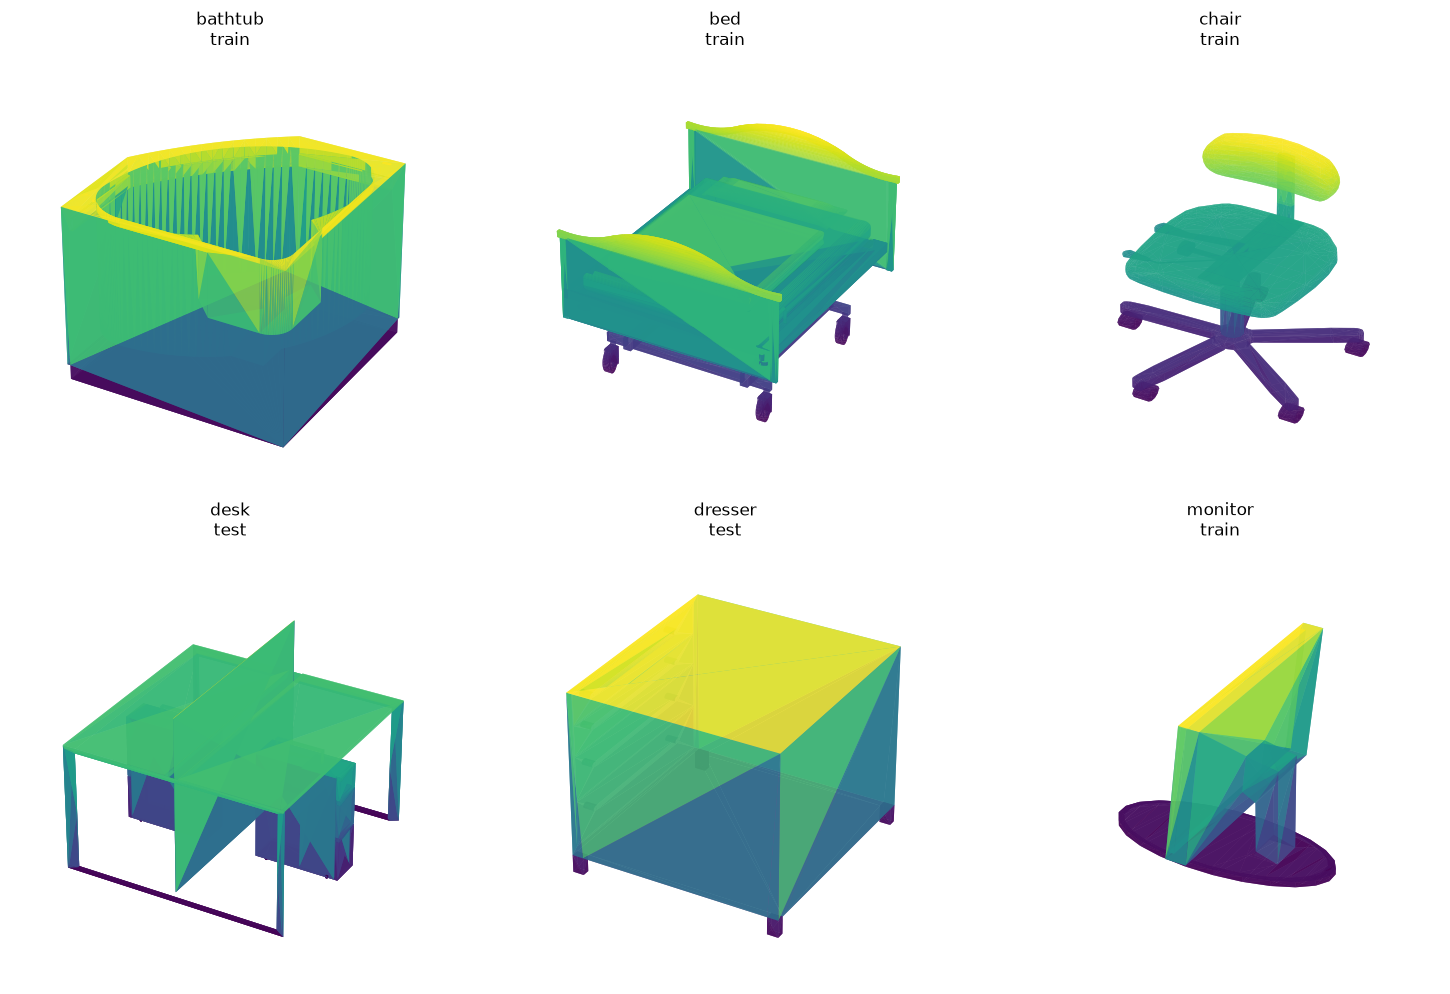

In [5]:
import open3d as o3d
import matplotlib.pyplot as plt
import numpy as np
from itertools import cycle

def visualize_multiple_objects(df, num_objects=6):
    """Визуализация нескольких 3D-моделей в одном окне"""
    fig = plt.figure(figsize=(15, 10))

    # Берем случайные объекты из разных классов
    samples = []
    classes = df['class'].unique()

    for i, class_name in enumerate(classes[:num_objects]):
        class_df = df[df['class'] == class_name]
        if len(class_df) > 0:
            sample = class_df.sample(1, random_state=42).iloc[0]
            samples.append(sample)

    for idx, sample in enumerate(samples):
        # Загружаем меш
        mesh = o3d.io.read_triangle_mesh(sample['object_path'])

        # Создаем subplot
        ax = fig.add_subplot(2, 3, idx + 1, projection='3d')

        # Преобразуем в numpy arrays
        vertices = np.asarray(mesh.vertices)
        triangles = np.asarray(mesh.triangles)

        # Визуализируем меш
        ax.plot_trisurf(vertices[:, 0], vertices[:, 1], vertices[:, 2],
                       triangles=triangles, alpha=0.8, cmap='viridis')

        ax.set_title(f"{sample['class']}\n{sample['split']}", fontsize=12)
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()

# Использование
visualize_multiple_objects(df)

In [6]:
import plotly.graph_objects as go
import numpy as np
from itertools import cycle

def plotly_3d_visualization(df, num_samples=1):
    """Интерактивная 3D визуализация одного объекта с Plotly"""
    colors = cycle(['red', 'blue', 'green', 'orange', 'purple', 'brown'])

    fig = go.Figure()

    # Берем только один класс
    class_name = df['class'].unique()[2]
    class_df = df[df['class'] == class_name]

    if len(class_df) > 0:
        sample = class_df.sample(1, random_state=42).iloc[0]
        mesh = o3d.io.read_triangle_mesh(sample['object_path'])

        vertices = np.asarray(mesh.vertices)
        triangles = np.asarray(mesh.triangles)

        color = next(colors)

        fig.add_trace(go.Mesh3d(
            x=vertices[:, 0],
            y=vertices[:, 1],
            z=vertices[:, 2],
            i=triangles[:, 0],
            j=triangles[:, 1],
            k=triangles[:, 2],
            color=color,
            opacity=0.9,
            name=f"{sample['class']} ({sample['split']})",
            showscale=False
        ))

    fig.update_layout(
        title=f"3D Модель: {sample['class']}",
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Z',
            aspectmode='data',
            camera=dict(
                eye=dict(x=1.5, y=1.5, z=1.5)
            )
        ),
        width=700,
        height=600
    )

    fig.show()

# Использование - покажет один случайный объект
plotly_3d_visualization(df)

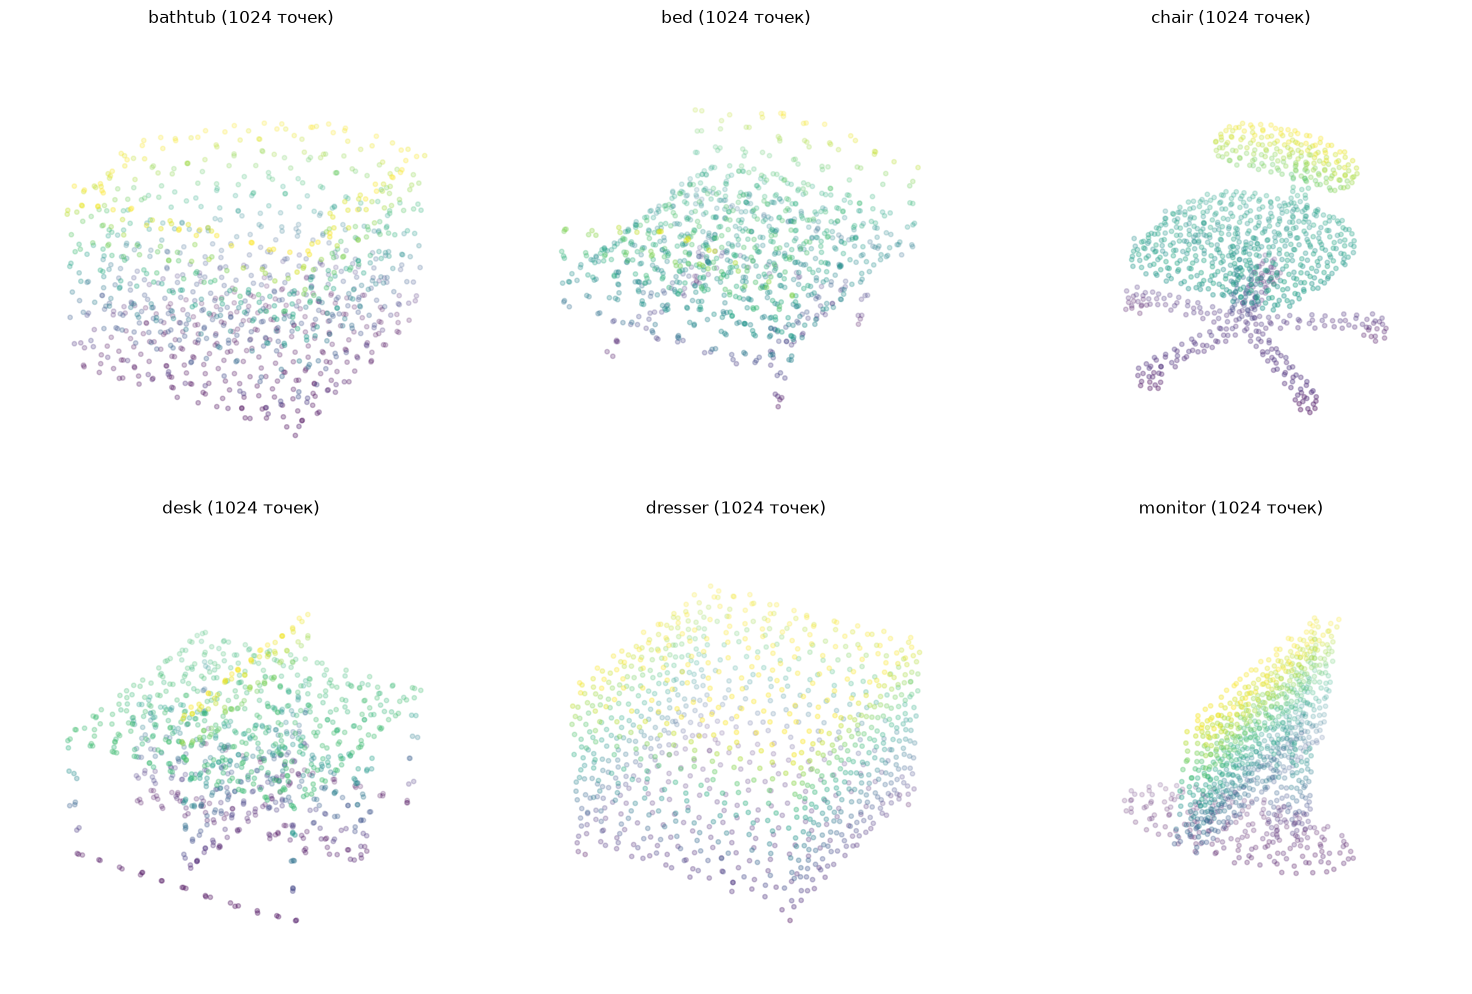

In [7]:
def visualize_point_clouds(df, num_points=1024):
    """Визуализация облаков точек вместо мешей"""
    fig = plt.figure(figsize=(15, 10))

    samples = []
    classes = df['class'].unique()

    for i, class_name in enumerate(classes[:6]):
        class_df = df[df['class'] == class_name]
        if len(class_df) > 0:
            sample = class_df.sample(1, random_state=42).iloc[0]
            samples.append(sample)

    for idx, sample in enumerate(samples):
        # Загружаем меш и конвертируем в облако точек
        mesh = o3d.io.read_triangle_mesh(sample['object_path'])
        point_cloud = mesh.sample_points_poisson_disk(number_of_points=num_points)
        points = np.asarray(point_cloud.points)

        ax = fig.add_subplot(2, 3, idx + 1, projection='3d')
        ax.scatter(points[:, 0], points[:, 1], points[:, 2],
                  s=10, alpha=0.6, c=points[:, 2], cmap='viridis')

        ax.set_title(f"{sample['class']} ({len(points)} точек)")
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()

# Использование
visualize_point_clouds(df)